# 04 · Classification models (Unit IV)

Full training run: `python -m src.classification` (7 classifiers, GridSearchCV + TimeSeriesSplit, macro F1). This notebook loads its saved results and adds one live experiment.

In [1]:
# Make the project folder importable (notebooks live in notebooks/)
import sys, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import Image, display
from config import project_config as cfg
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
import json
meta = json.load(open(cfg.MODELS_DIR / 'classification_model_meta.json'))
{k: meta[k] for k in ['thresholds', 'selected_model', 'best_params', 'validation_metrics', 'test_metrics']}

{'thresholds': {'low_upper': 64.0, 'medium_upper': 198.0},
 'selected_model': 'Logistic Regression',
 'best_params': {'C': 10},
 'validation_metrics': {'accuracy': 0.9207,
  'precision_macro': 0.8968,
  'recall_macro': 0.8881,
  'f1_macro': 0.8922,
  'roc_auc_ovr_macro': 0.98},
 'test_metrics': {'accuracy': 0.8386,
  'precision_macro': 0.8374,
  'recall_macro': 0.8041,
  'f1_macro': 0.816,
  'roc_auc_ovr_macro': 0.9461}}

In [3]:
pd.read_csv(cfg.METRICS_DIR / 'class_distribution.csv')

,demand_level,train,validation,test
0,Low,4334,498,636
1,Medium,4319,383,537
2,High,4350,1327,995


In [4]:
pd.read_csv(cfg.METRICS_DIR / 'classification_validation_results.csv').sort_values('f1_macro', ascending=False)

,model,best_params,cv_f1_macro,train_f1_macro,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr_macro
1,Logistic Regression,"{""C"": 10}",0.7819,0.8715,0.9207,0.8968,0.8881,0.8922,0.9210,0.9800
4,Random Forest,"{""max_depth"": null, ""min_samples_leaf"": 1}",0.7279,1.0000,0.9004,0.8612,0.8924,0.8743,0.9038,0.9767
3,Decision Tree,"{""max_depth"": 10, ""min_samples_leaf"": 20}",0.7494,0.8627,0.8981,0.8579,0.8744,0.8656,0.8998,0.9719
6,Naive Bayes (Gaussian),"{""var_smoothing"": 1e-09}",0.7741,0.6649,0.8922,0.8434,0.8673,0.8543,0.8930,0.9655
5,SVM (RBF kernel),"{""C"": 10}",0.7354,0.9753,0.8718,0.8370,0.8751,0.8493,0.8786,0.9563
2,KNN,"{""n_neighbors"": 15, ""weights"": ""distance""}",0.6883,1.0000,0.7948,0.7757,0.8377,0.7824,0.8107,0.9462
0,Dummy (most frequent),{},0.1492,0.1671,0.6010,0.2003,0.3333,0.2503,0.4512,0.5000


In [5]:
pd.read_csv(cfg.METRICS_DIR / 'classification_test_results.csv').sort_values('f1_macro', ascending=False)

,model,selected_on_validation,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr_macro
5,SVM (RBF kernel),False,0.8372,0.8285,0.8183,0.8217,0.8391,0.9441
1,Logistic Regression,True,0.8386,0.8374,0.8041,0.8160,0.8345,0.9461
4,Random Forest,False,0.8326,0.8197,0.8133,0.8158,0.8338,0.9477
3,Decision Tree,False,0.8072,0.7851,0.7786,0.7802,0.8026,0.9142
2,KNN,False,0.7500,0.7624,0.7669,0.7498,0.7593,0.9186
6,Naive Bayes (Gaussian),False,0.7735,0.7883,0.7114,0.7217,0.7518,0.8736
0,Dummy (most frequent),False,0.4589,0.1530,0.3333,0.2097,0.2887,0.5000


In [6]:
print((cfg.METRICS_DIR / 'classification_report_test.txt').read_text())

              precision    recall  f1-score   support

         Low     0.9621    0.8381    0.8958       636
      Medium     0.7269    0.6145    0.6660       537
        High     0.8233    0.9598    0.8863       995

    accuracy                         0.8386      2168
   macro avg     0.8374    0.8041    0.8160      2168
weighted avg     0.8401    0.8386    0.8345      2168



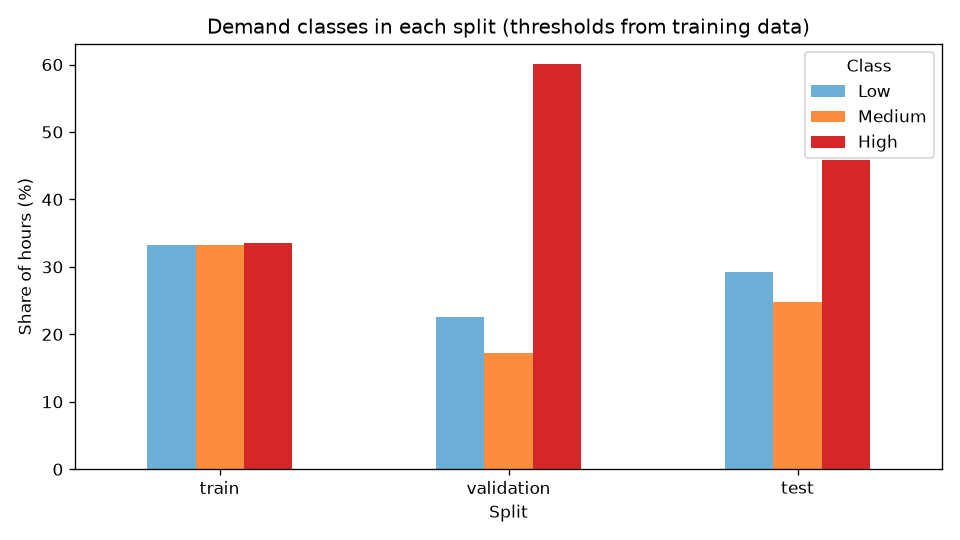

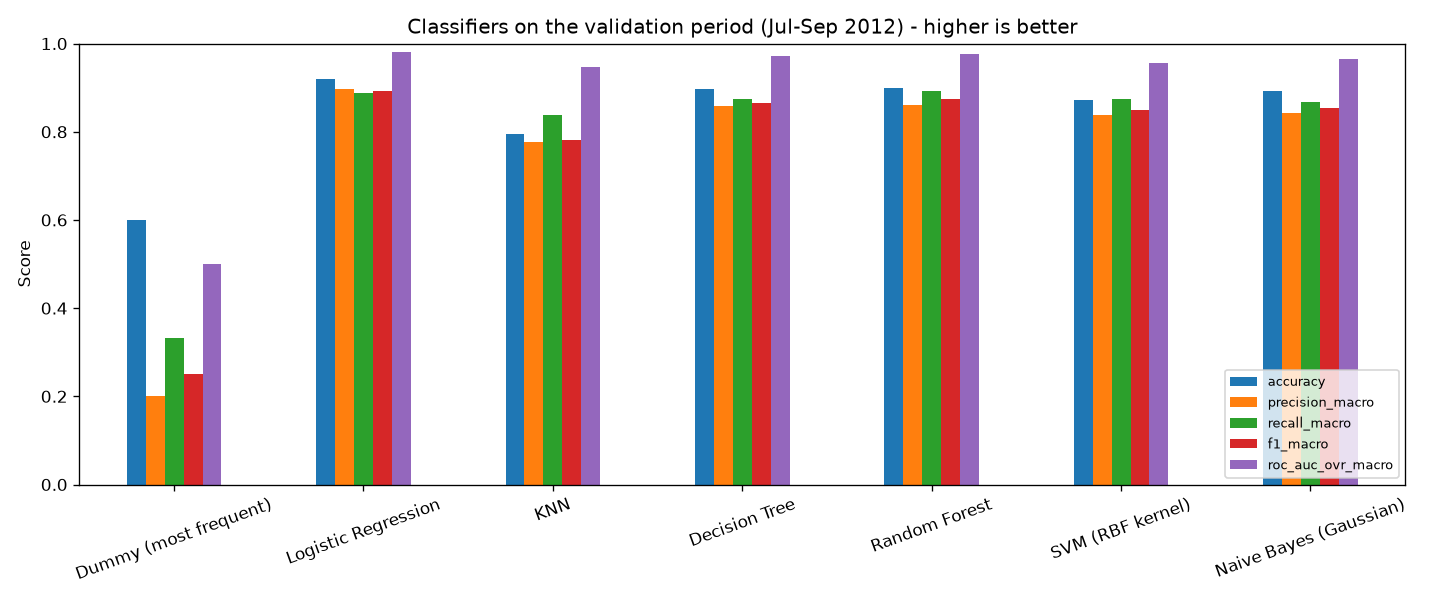

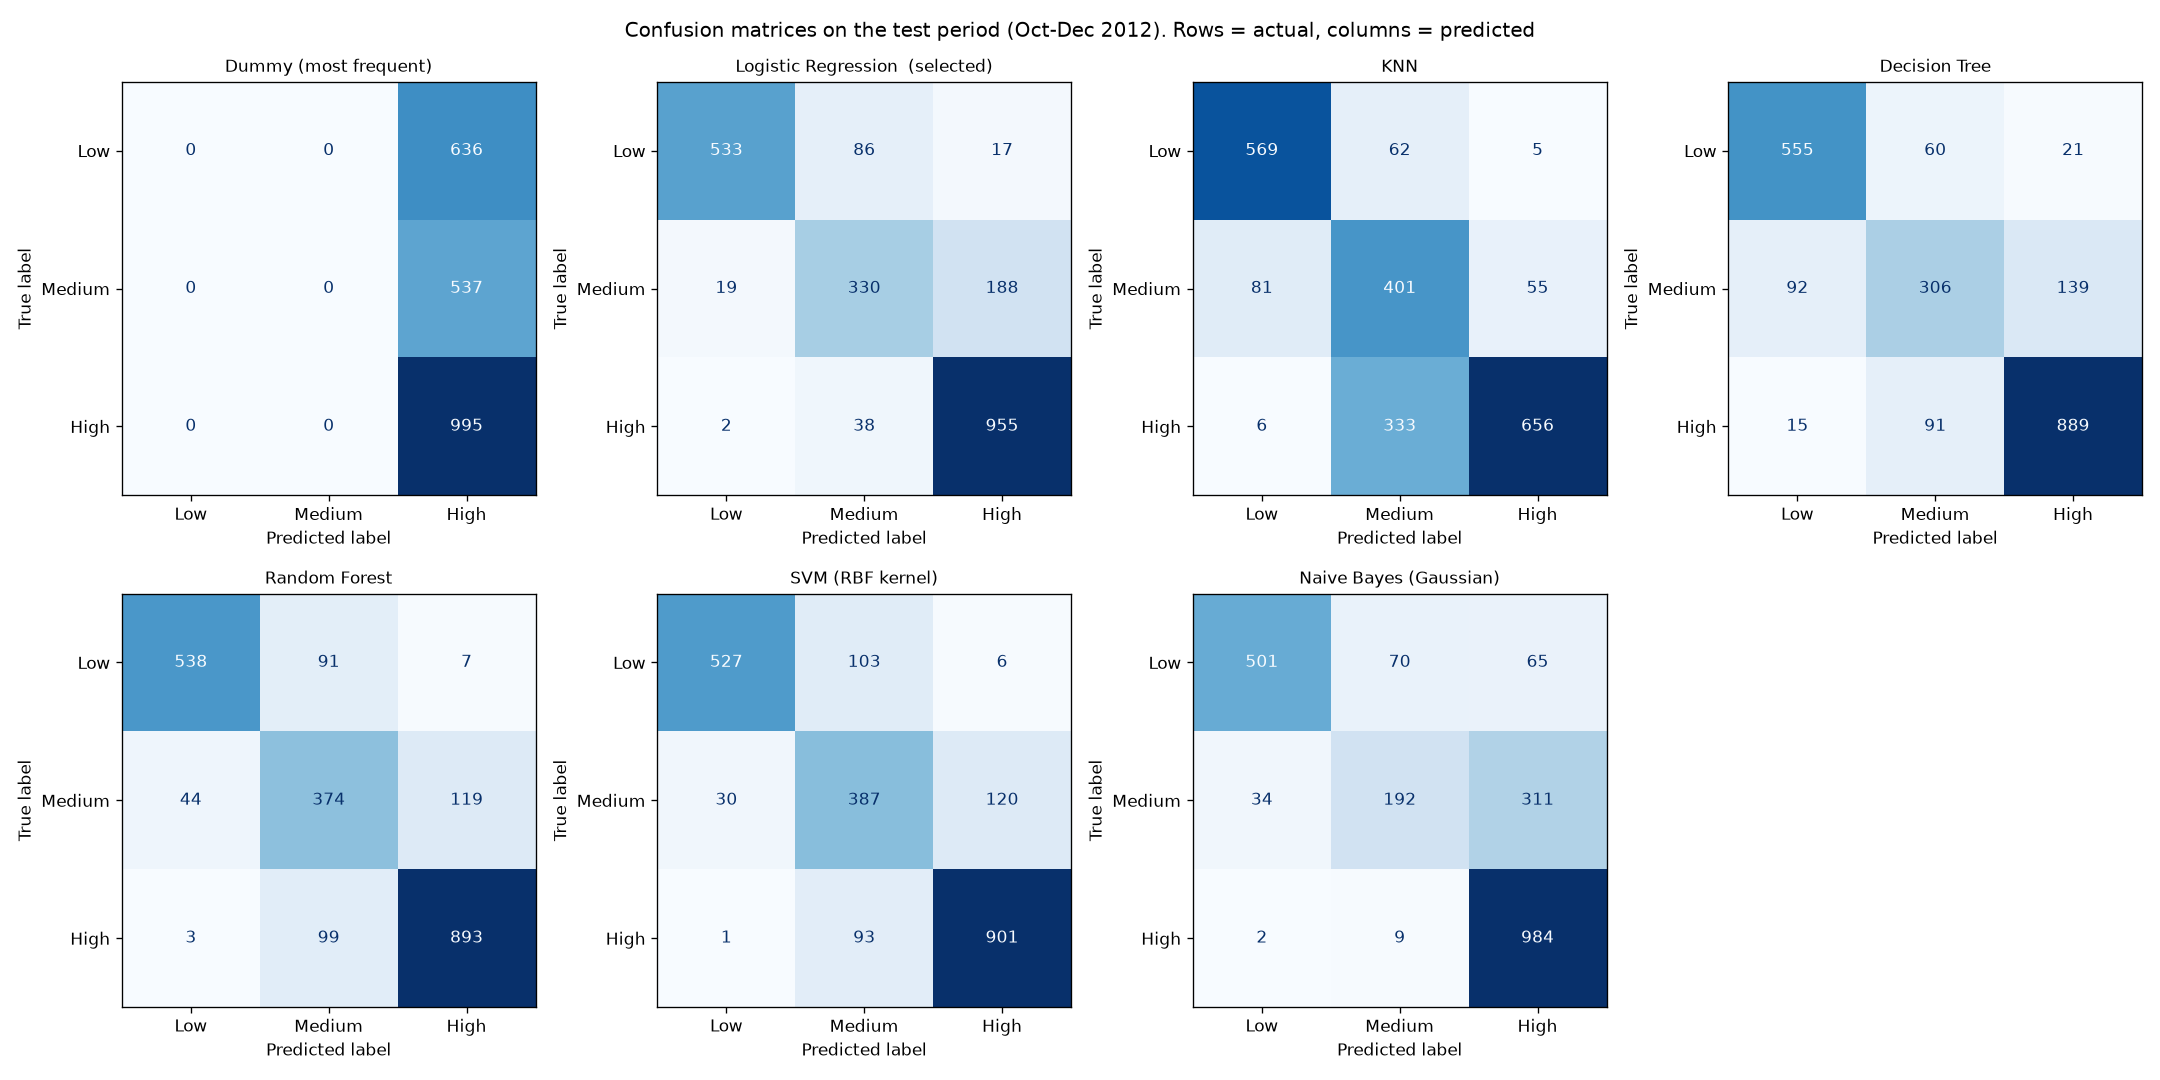

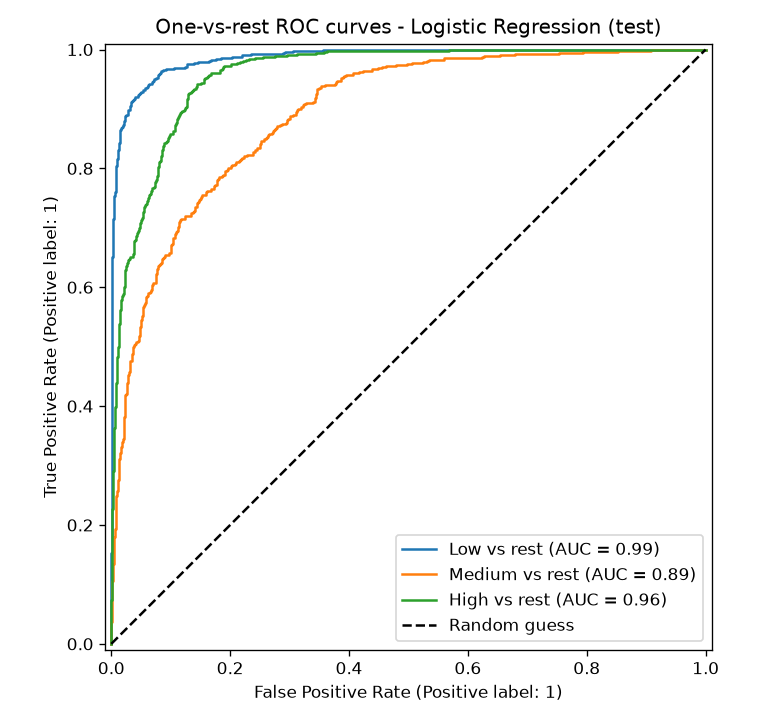

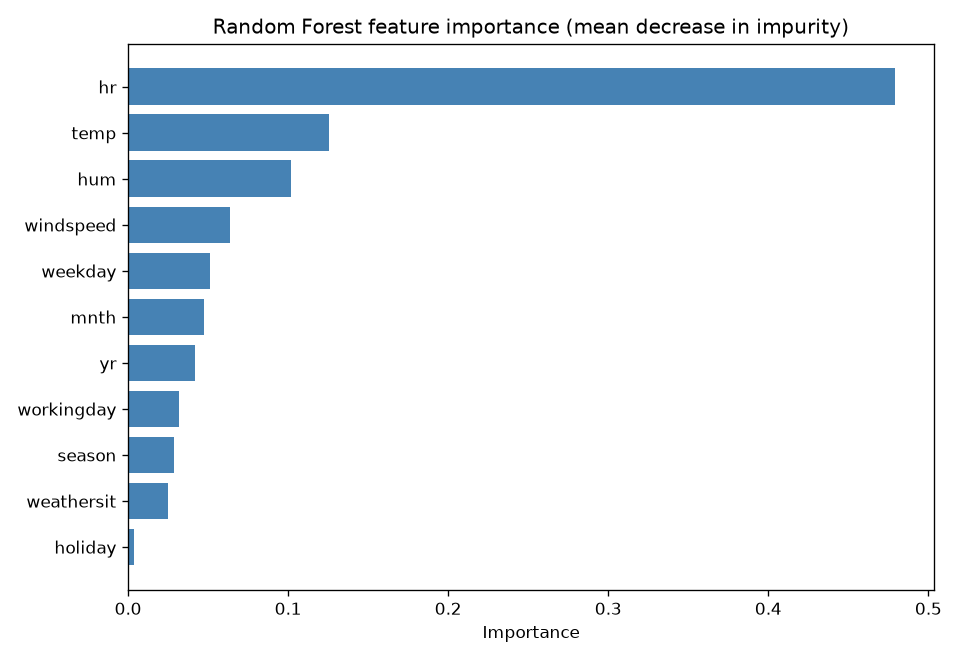

In [7]:
for name in ['15_class_distribution', '16_classification_validation_comparison', '17_confusion_matrices_test', '18_roc_curves_test', '19_random_forest_feature_importance']:
    display(Image(filename=str(cfg.FIGURES_DIR / f'{name}.png')))

## Live experiment: why KNN needs feature scaling
KNN compares distances. Without scaling, a column with a large range dominates the distance. Same KNN, same data, with and without `StandardScaler`, using raw numeric inputs.

In [8]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from src.data_loader import load_hour_data
from src.feature_engineering import add_features
from src.preprocessing import chronological_split
from src.classification import compute_thresholds, label_demand
tr, va, te = chronological_split(add_features(load_hour_data()))
t = compute_thresholds(tr['cnt'])
ytr, yva = label_demand(tr['cnt'], t), label_demand(va['cnt'], t)
# real units: hour 0-23, temperature in °C, humidity in %, wind 0-67
def raw(d):
    return pd.DataFrame({'hr': d['hr'], 'workingday': d['workingday'],
                         'temp_c': d['temp'] * 47 - 8, 'hum_pct': d['hum'] * 100, 'wind': d['windspeed'] * 67})
for name, model in [('without scaling', KNeighborsClassifier(15)),
                    ('with StandardScaler', make_pipeline(StandardScaler(), KNeighborsClassifier(15)))]:
    model.fit(raw(tr), ytr)
    print(f'{name:20s} validation macro F1 = {f1_score(yva, model.predict(raw(va)), average="macro"):.4f}')

without scaling      validation macro F1 = 0.6559
with StandardScaler  validation macro F1 = 0.7411
